<a href="https://colab.research.google.com/github/Ahaaaaan/Containment-Protocol/blob/main/Week2/NCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import os
from google.colab import drive
import glob
from matplotlib.animation import FuncAnimation
# Install TensorFlow via terminal if needed: pip install tensorflow
import tensorflow as tf
from tensorflow.keras import layers, models
sobel_x = np.matrix([[-1, 0, +1],
                     [-2, 0, +2],
                     [-1, 0, +1]], dtype=np.float32)/8.0
sobel_y = tf.constant(sobel_x.T)
sobel_x = tf.constant(sobel_x)
sobel_x = tf.reshape(sobel_x, [3,3,1,1])
sobel_x = tf.repeat(sobel_x, 16, axis=2)

sobel_y = tf.reshape(sobel_y, [3,3,1,1])
sobel_y = tf.repeat(sobel_y, 16, axis=2)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
from google.colab import drive
import glob

In [ ]:
def perceive(state_grid):
  # Convolve sobel filters with states
  # in x, y and channel dimension.
  channels = 16

  # Concatenate the cell’s state channels,
  # the gradients of channels in x and
  # the gradient of channels in y.

  gx = tf.nn.depthwise_conv2d(
    state_grid,
    sobel_x,
    strides=[1,1,1,1],
    padding='SAME'
  )

  gy = tf.nn.depthwise_conv2d(
      state_grid,
      sobel_y,
      strides=[1,1,1,1],
      padding='SAME'
  )
  perception = tf.concat(
    [state_grid, gx, gy],
    axis=-1
  ) #Stacks the 16 channels of each to form a 48 channel dimension. The shape is now (batch, 64, 64, 48)
  return perception

In [ ]:
def alive_check(state):

  alpha = state[...,1:2]
  pooled = tf.nn.max_pool2d(
      alpha,
      ksize=3,
      strides=1,
      padding='SAME'
  )
  mask = tf.cast(pooled > 0.1, tf.float32)
  state = state * mask
  return state

In [ ]:
class NCAModel(tf.keras.Model):
    def __init__(self):
        super().__init__()

        self.dense1 = tf.keras.layers.Conv2D(
            filters=128,
            kernel_size=1,
            activation='relu'
        )

        self.dense2 = tf.keras.layers.Conv2D(
            filters=16,
            kernel_size=1,
            kernel_initializer='zeros'
        )

    def call(self, perception):
        x = self.dense1(perception)
        ds = self.dense2(x)
        return ds

model = NCAModel()
dummy = tf.zeros((1,64,64,48))
model(dummy) # Uses the dummy to build the Weights and Biases matrices
optimizer = tf.keras.optimizers.Adam(learning_rate=3e-3)
#model.load_weights(latest_checkpoint)
print(model.summary())

Model: "nca_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (1, 64, 64, 128)       │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 64, 64, 16)        │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,336 (32.56 KB)

 Trainable params: 8,336 (32.56 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
def nca_step(state, model):

    perception = perceive(state)

    ds = model(perception)

    update_mask = tf.cast(
    tf.random.uniform(
        tf.concat([tf.shape(ds)[:3], tf.constant([1])], axis = 0)
    ) < 0.5,
    tf.float32
    )

    ds *= update_mask

    state = state + ds

    return state

In [ ]:
@tf.function
def train_step(initial_state, target, steps):

    with tf.GradientTape() as tape: #Try to understand this later

        state = initial_state

        for _ in range(steps): #Fixed number of updates for now
            state = nca_step(state, model)
            state = alive_check(state)


        loss = tf.reduce_mean(
            (state[..., 0:1] - target[..., 0:1])**2
        )

    grads = tape.gradient(
            loss,
            model.trainable_variables
    )

    optimizer.apply_gradients(
            zip(grads, model.trainable_variables)
    )

    return loss

In [ ]:
GRID_SIZE = 64
CHANNELS = 16

seed = tf.zeros(
    [1, GRID_SIZE, GRID_SIZE, CHANNELS],
    dtype=tf.float32
)

center = GRID_SIZE // 2

indices = [[0, center, center, 1], [0, center-1, center, 1], [0, center+1, center, 1], [0, center, center-1, 1], [0, center-1, center-1, 1], [0, center+1, center-1, 1], [0, center, center+1, 1], [0, center-1, center+1, 1], [0, center+1, center+1, 1]]  # alpha channel - Alive v/s Dead
#indices = [[0, center, center, 1]]
updates = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
#updates = [1.0]
seed = tf.tensor_scatter_nd_update(
    seed,
    indices,
    updates
)

def make_ring_target():
    state = np.zeros(
        (1, GRID_SIZE, GRID_SIZE, CHANNELS), #NHWC format
        dtype=np.float32
    )

    y, x = np.ogrid[:GRID_SIZE, :GRID_SIZE]

    cx = GRID_SIZE // 2
    cy = GRID_SIZE // 2

    outer_radius = 10
    inner_radius = 0

    dist_sq = (x - cx)**2 + (y - cy)**2

    ring = (
        (dist_sq <= outer_radius**2) &
        (dist_sq >= inner_radius**2)
    )

    state[0, :, :, 0] = ring.astype(np.float32)

    return tf.convert_to_tensor(state)

target = make_ring_target()

In [ ]:
def get_image():
  state = nca_step(seed, model)
  state = alive_check(state)
  for _ in range(23):
    state = nca_step(state, model)
    state = alive_check(state)
  plt.imshow(state[0,:,:,1], cmap='gray')
  plt.show()
  plt.imshow(state[0,:,:,0], cmap='gray')
  plt.show()
  pooled = tf.nn.max_pool2d(
      state[..., 1:2],
      ksize=3,
      strides=1,
      padding='SAME'
  )
  mask = tf.cast(pooled > 0.1, tf.float32)
  plt.imshow(state[0,:,:,0], cmap='gray')
  plt.show()

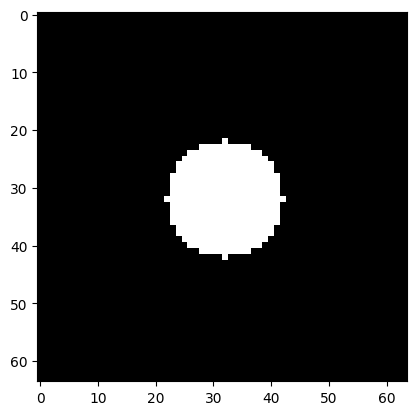

In [ ]:
plt.imshow(target[0, :, :, 0], cmap='gray')
plt.show()

Training is done below. So far, done only starting from the seed.

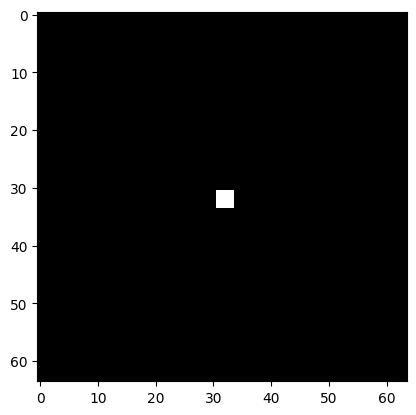

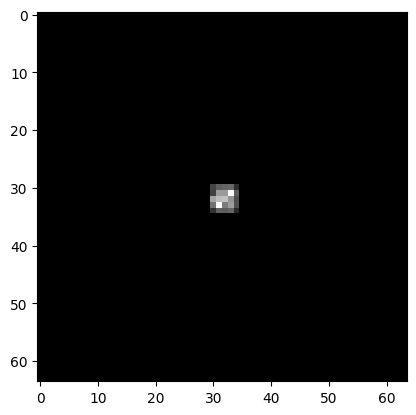

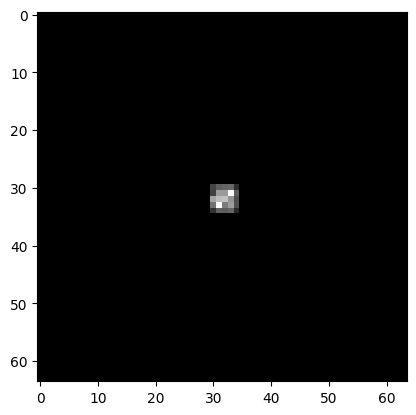

tf.Tensor(0.07739258, shape=(), dtype=float32)
tf.Tensor(0.07543186, shape=(), dtype=float32)
tf.Tensor(0.07170513, shape=(), dtype=float32)
tf.Tensor(0.074025534, shape=(), dtype=float32)


tf.Tensor(0.06885893, shape=(), dtype=float32)


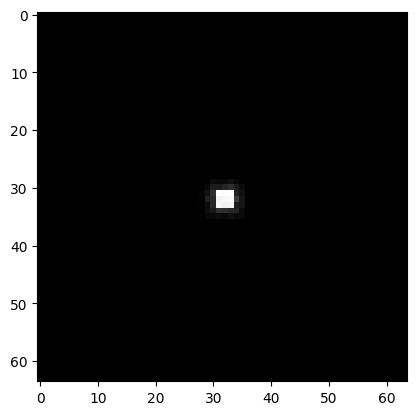

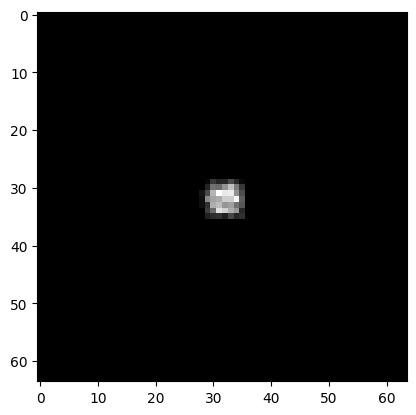

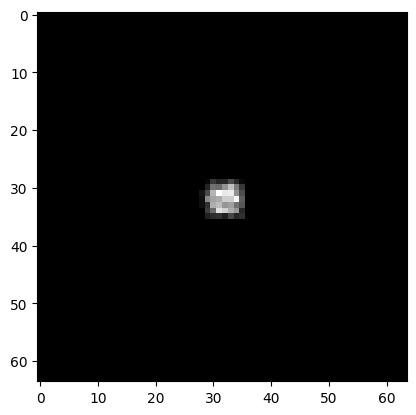

tf.Tensor(0.07160585, shape=(), dtype=float32)
tf.Tensor(0.071747035, shape=(), dtype=float32)
tf.Tensor(0.07155385, shape=(), dtype=float32)
tf.Tensor(0.07057498, shape=(), dtype=float32)
tf.Tensor(0.06832604, shape=(), dtype=float32)


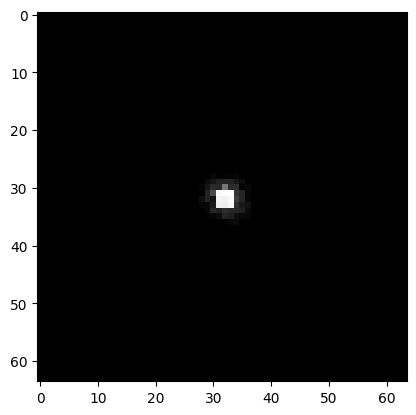

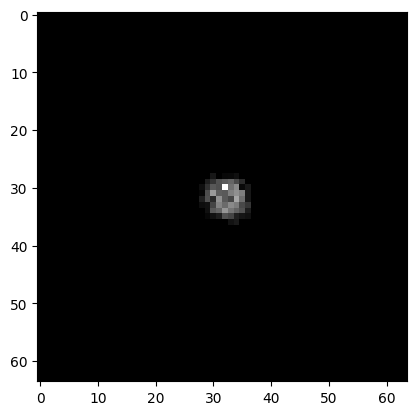

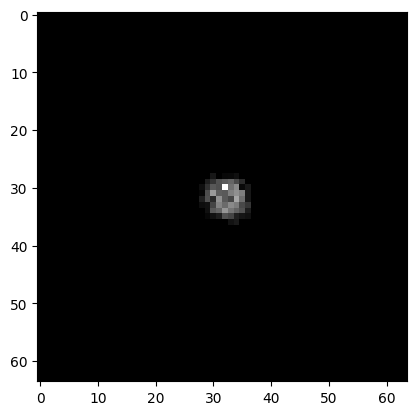

tf.Tensor(0.06791263, shape=(), dtype=float32)
tf.Tensor(0.070963755, shape=(), dtype=float32)
tf.Tensor(0.06587665, shape=(), dtype=float32)
tf.Tensor(0.06696501, shape=(), dtype=float32)
tf.Tensor(0.062137518, shape=(), dtype=float32)


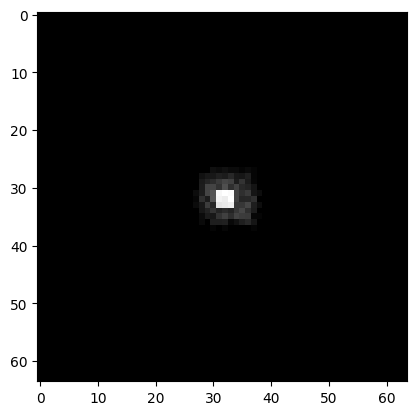

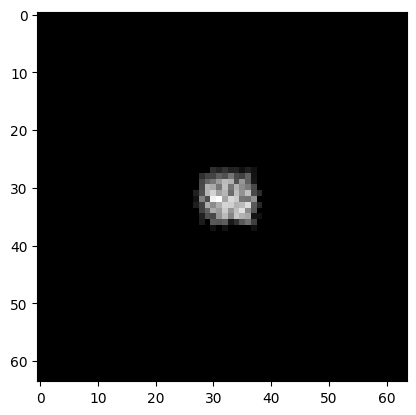

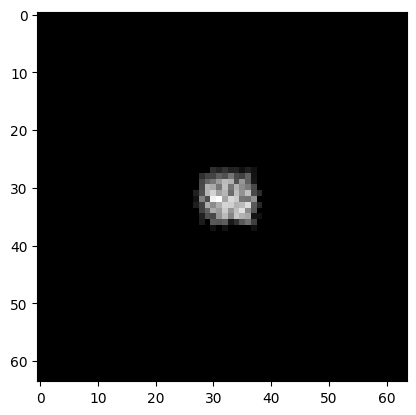

tf.Tensor(0.06479257, shape=(), dtype=float32)
tf.Tensor(0.060600586, shape=(), dtype=float32)
tf.Tensor(0.04832539, shape=(), dtype=float32)
tf.Tensor(0.05762499, shape=(), dtype=float32)
tf.Tensor(0.04479759, shape=(), dtype=float32)


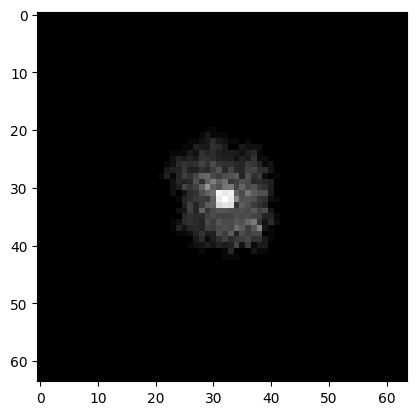

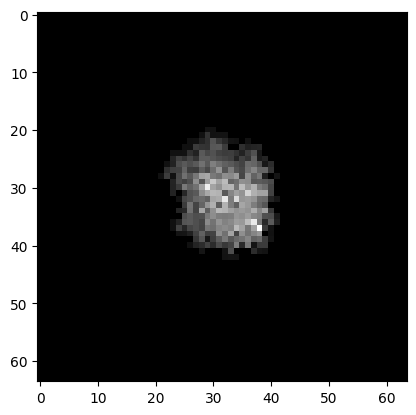

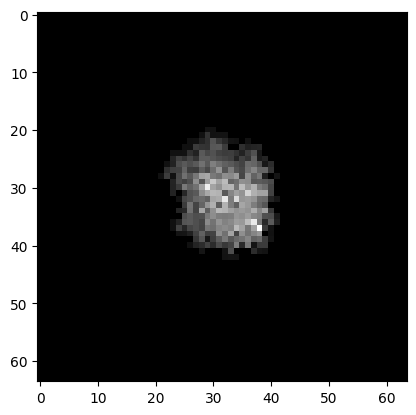

tf.Tensor(0.048376337, shape=(), dtype=float32)
tf.Tensor(0.03040307, shape=(), dtype=float32)
tf.Tensor(0.025153818, shape=(), dtype=float32)
tf.Tensor(0.022540696, shape=(), dtype=float32)
tf.Tensor(0.066647366, shape=(), dtype=float32)


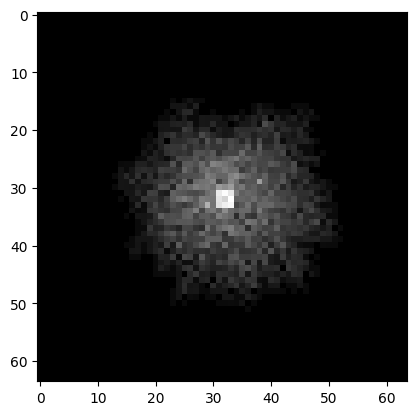

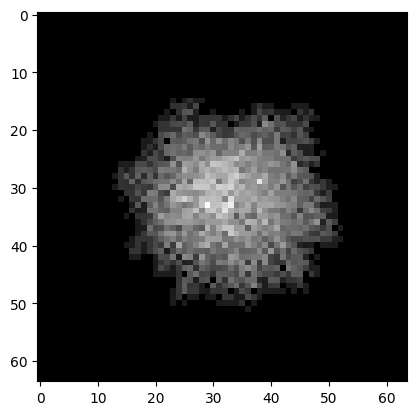

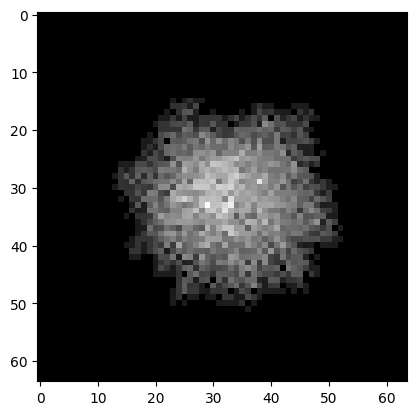

tf.Tensor(0.030778436, shape=(), dtype=float32)
tf.Tensor(0.027874405, shape=(), dtype=float32)
tf.Tensor(0.05090037, shape=(), dtype=float32)
tf.Tensor(0.048741955, shape=(), dtype=float32)
tf.Tensor(0.04163275, shape=(), dtype=float32)


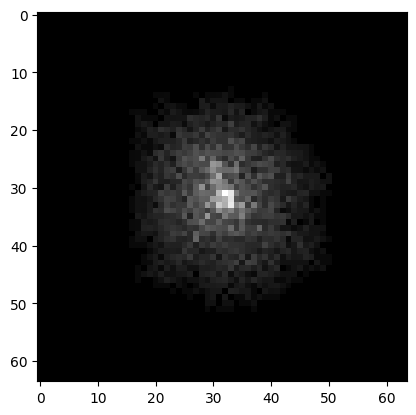

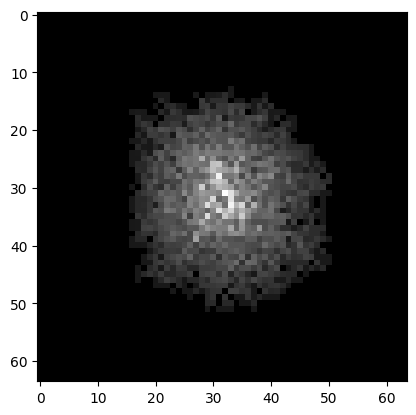

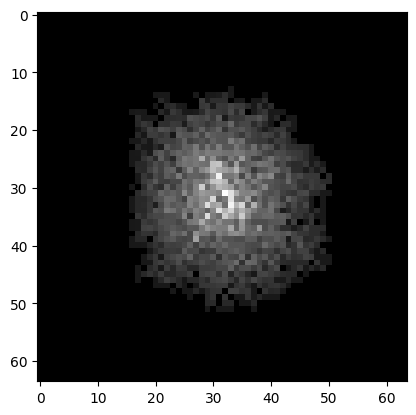

tf.Tensor(0.047186702, shape=(), dtype=float32)
tf.Tensor(0.039371476, shape=(), dtype=float32)
tf.Tensor(0.043572634, shape=(), dtype=float32)
tf.Tensor(0.034597374, shape=(), dtype=float32)
tf.Tensor(0.059089538, shape=(), dtype=float32)


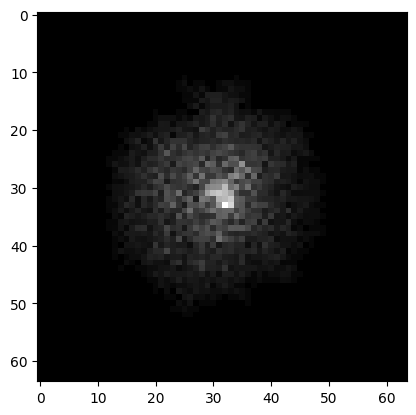

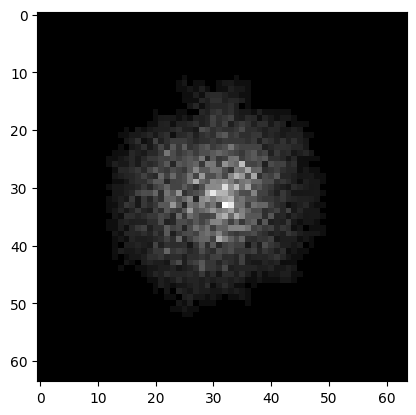

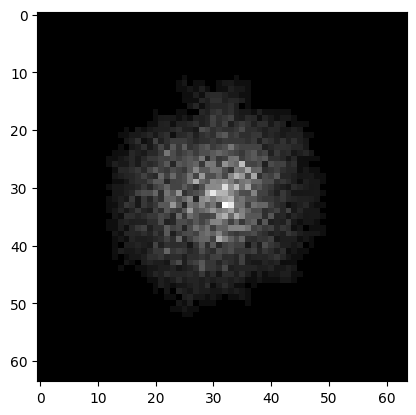

tf.Tensor(0.042759348, shape=(), dtype=float32)
tf.Tensor(0.045839358, shape=(), dtype=float32)
tf.Tensor(0.0427532, shape=(), dtype=float32)
tf.Tensor(0.03657639, shape=(), dtype=float32)
tf.Tensor(0.04547803, shape=(), dtype=float32)


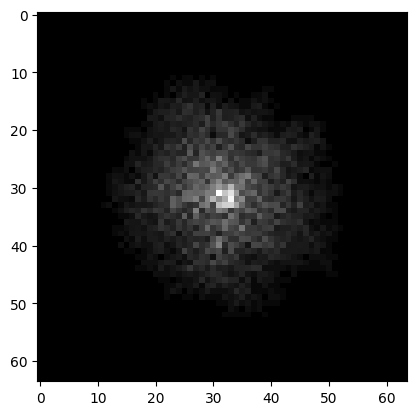

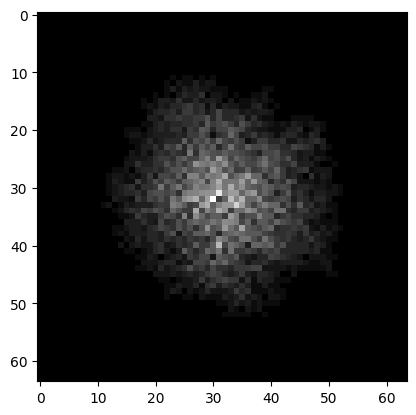

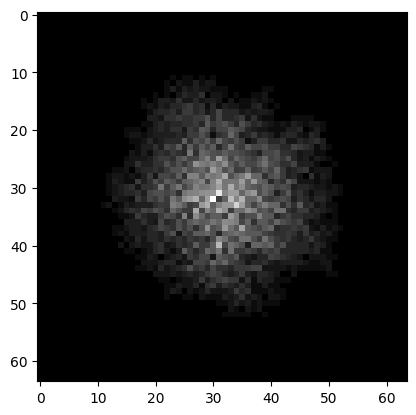

tf.Tensor(0.049810562, shape=(), dtype=float32)
tf.Tensor(0.0379128, shape=(), dtype=float32)
tf.Tensor(0.03370164, shape=(), dtype=float32)
tf.Tensor(0.034348555, shape=(), dtype=float32)
tf.Tensor(0.03024103, shape=(), dtype=float32)


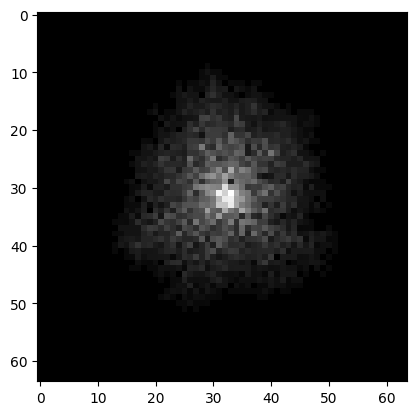

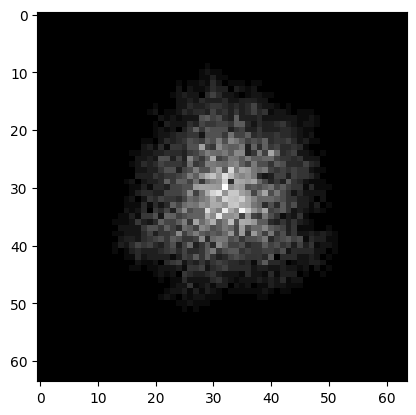

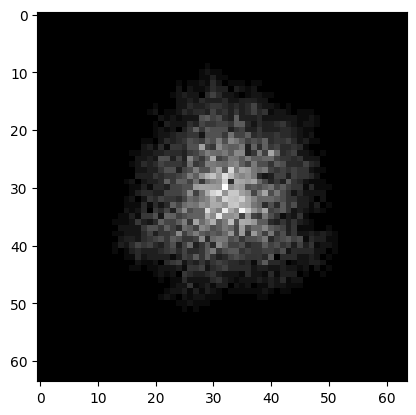

tf.Tensor(0.04183694, shape=(), dtype=float32)
tf.Tensor(0.03928609, shape=(), dtype=float32)
tf.Tensor(0.029109044, shape=(), dtype=float32)
tf.Tensor(0.037127458, shape=(), dtype=float32)
tf.Tensor(0.037420444, shape=(), dtype=float32)


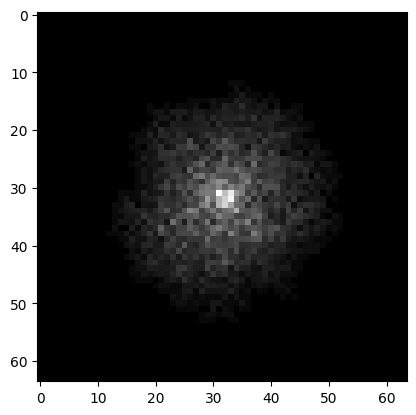

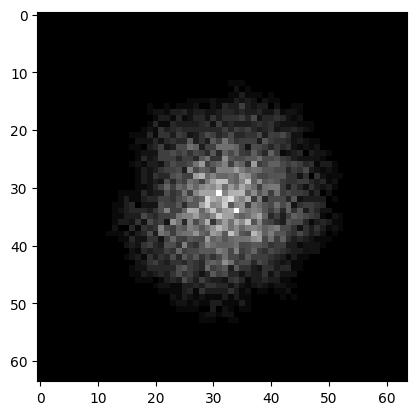

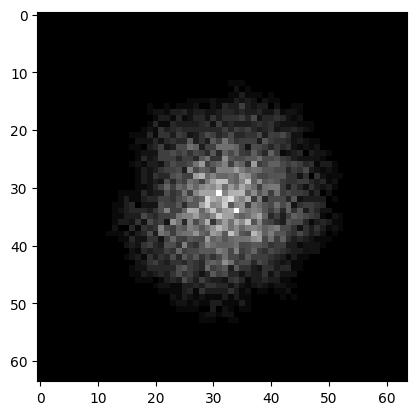

tf.Tensor(0.031354528, shape=(), dtype=float32)
tf.Tensor(0.036118332, shape=(), dtype=float32)
tf.Tensor(0.032894745, shape=(), dtype=float32)
tf.Tensor(0.045631737, shape=(), dtype=float32)
tf.Tensor(0.04321064, shape=(), dtype=float32)


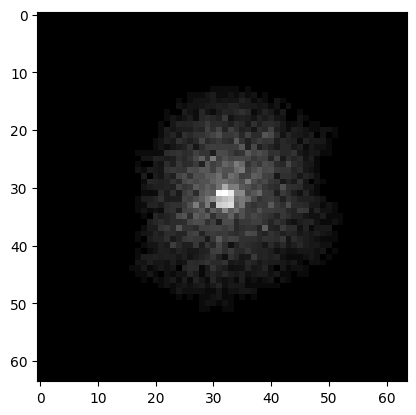

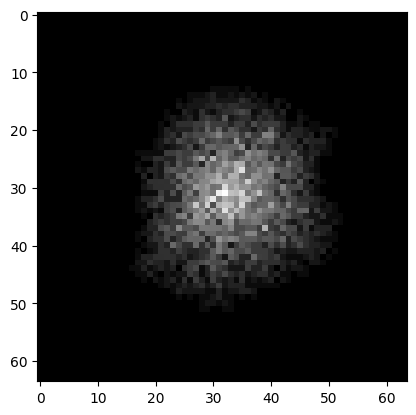

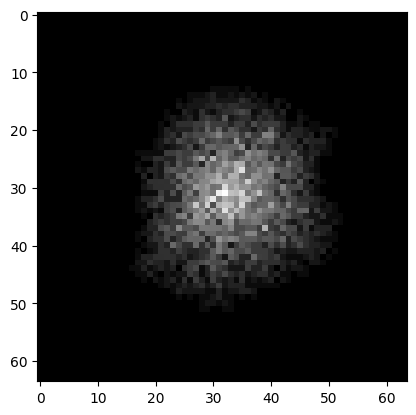

tf.Tensor(0.04328157, shape=(), dtype=float32)
tf.Tensor(0.037672624, shape=(), dtype=float32)
tf.Tensor(0.042023506, shape=(), dtype=float32)
tf.Tensor(0.035316058, shape=(), dtype=float32)
tf.Tensor(0.034814697, shape=(), dtype=float32)


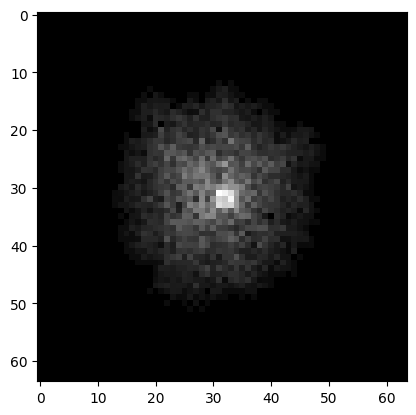

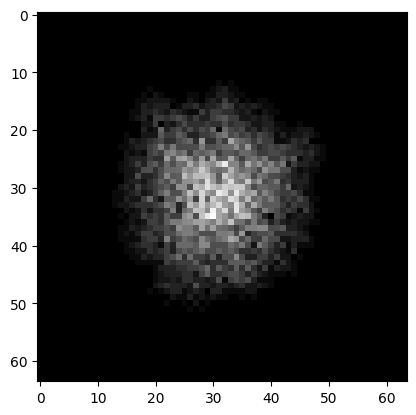

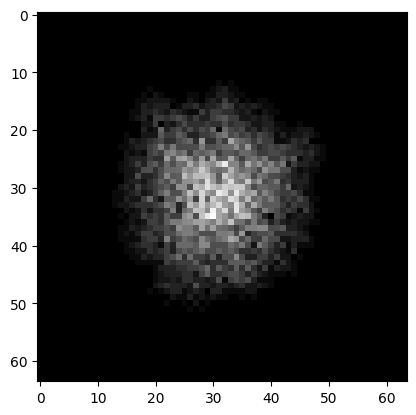

tf.Tensor(0.036250215, shape=(), dtype=float32)
tf.Tensor(0.034824293, shape=(), dtype=float32)
tf.Tensor(0.040230714, shape=(), dtype=float32)
tf.Tensor(0.040631533, shape=(), dtype=float32)
tf.Tensor(0.04067447, shape=(), dtype=float32)


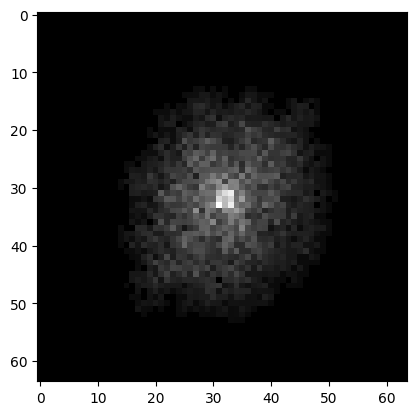

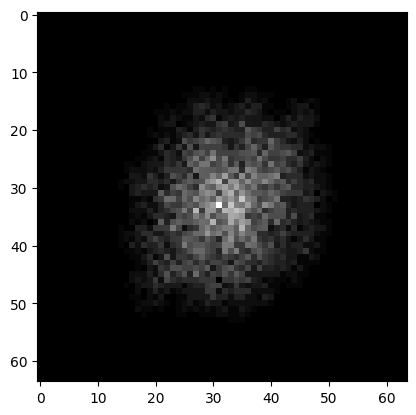

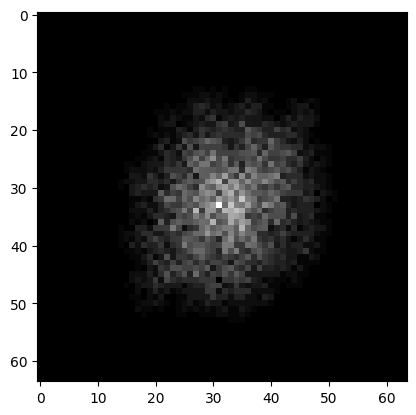

tf.Tensor(0.03150794, shape=(), dtype=float32)
tf.Tensor(0.030798841, shape=(), dtype=float32)
tf.Tensor(0.031220809, shape=(), dtype=float32)
tf.Tensor(0.037089158, shape=(), dtype=float32)
tf.Tensor(0.048043128, shape=(), dtype=float32)


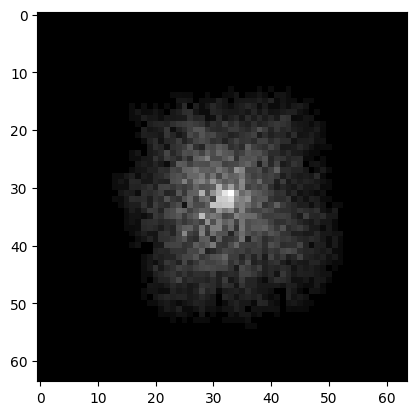

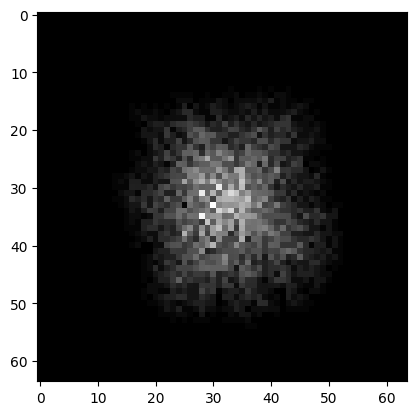

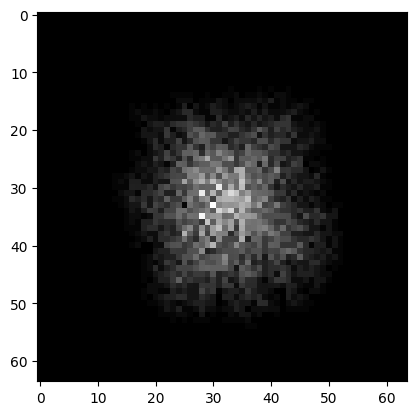

tf.Tensor(0.029808223, shape=(), dtype=float32)
tf.Tensor(0.038994726, shape=(), dtype=float32)
tf.Tensor(0.042015042, shape=(), dtype=float32)
tf.Tensor(0.033051368, shape=(), dtype=float32)
tf.Tensor(0.03986287, shape=(), dtype=float32)


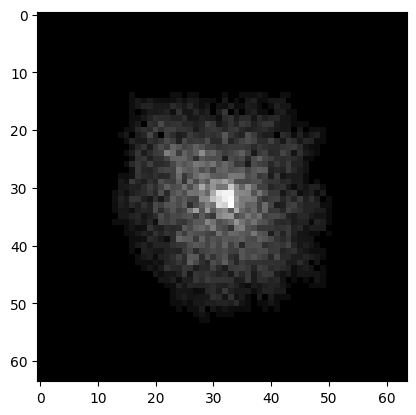

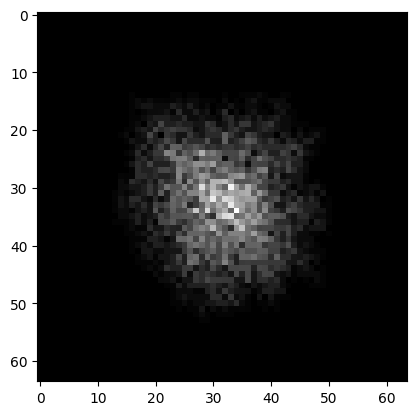

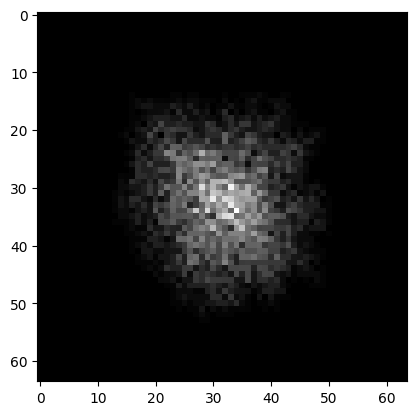

tf.Tensor(0.030893516, shape=(), dtype=float32)
tf.Tensor(0.034989744, shape=(), dtype=float32)
tf.Tensor(0.039414816, shape=(), dtype=float32)
tf.Tensor(0.032861818, shape=(), dtype=float32)
tf.Tensor(0.031573795, shape=(), dtype=float32)


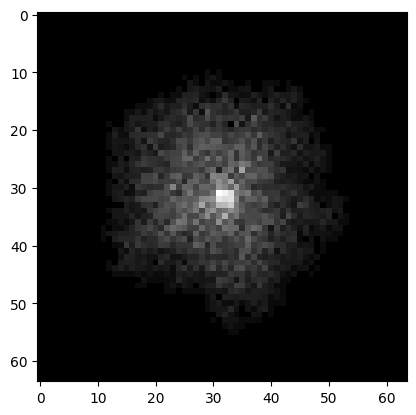

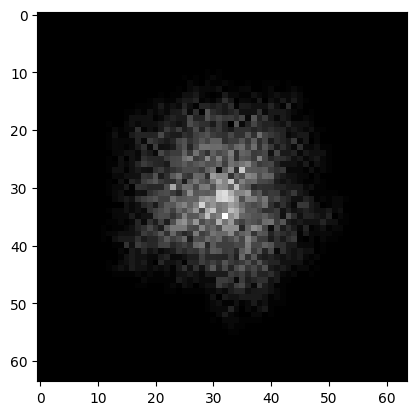

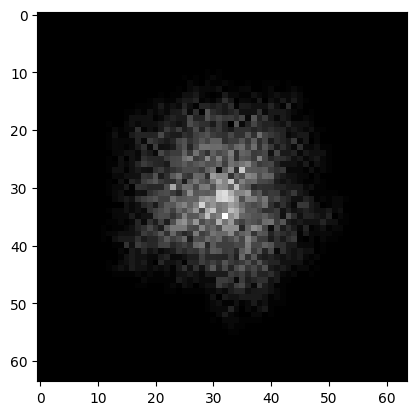

tf.Tensor(0.029298954, shape=(), dtype=float32)
tf.Tensor(0.030943971, shape=(), dtype=float32)
tf.Tensor(0.028580852, shape=(), dtype=float32)
tf.Tensor(0.03086832, shape=(), dtype=float32)
tf.Tensor(0.028094225, shape=(), dtype=float32)


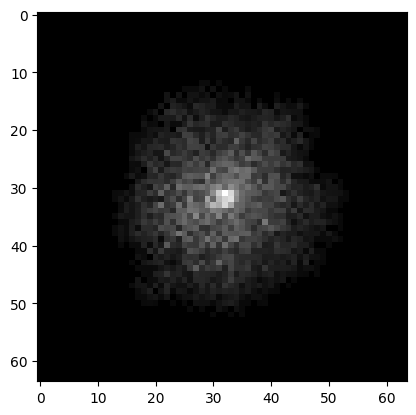

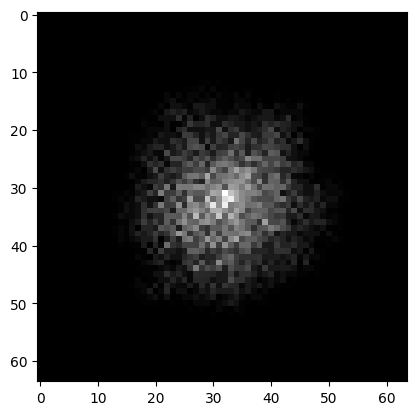

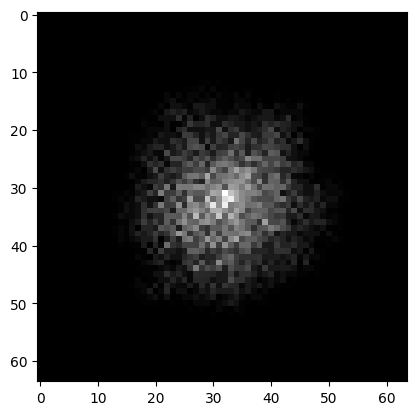

tf.Tensor(0.03802572, shape=(), dtype=float32)
tf.Tensor(0.05694291, shape=(), dtype=float32)
tf.Tensor(0.031101868, shape=(), dtype=float32)
tf.Tensor(0.03462109, shape=(), dtype=float32)
tf.Tensor(0.038516436, shape=(), dtype=float32)


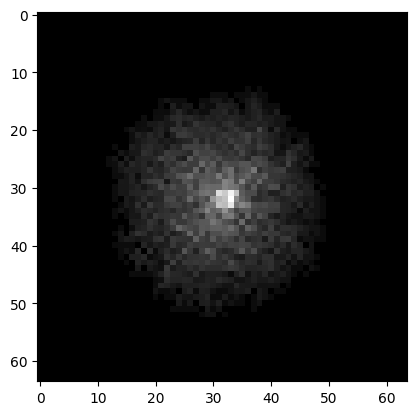

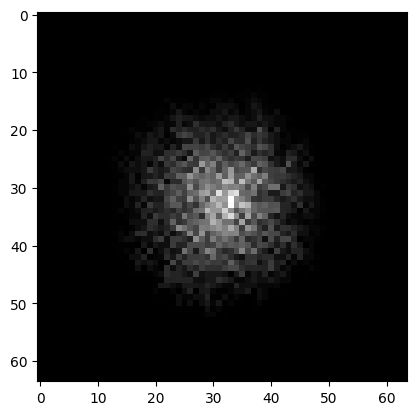

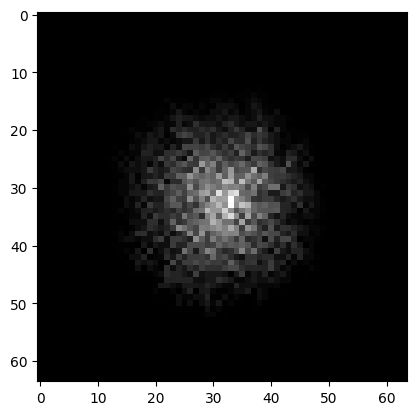

tf.Tensor(0.032076523, shape=(), dtype=float32)
tf.Tensor(0.03152827, shape=(), dtype=float32)
tf.Tensor(0.045441903, shape=(), dtype=float32)
tf.Tensor(0.035747968, shape=(), dtype=float32)
tf.Tensor(0.03120216, shape=(), dtype=float32)


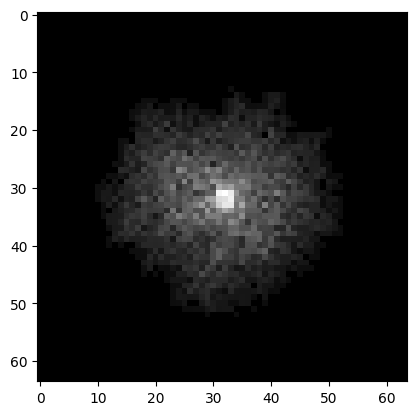

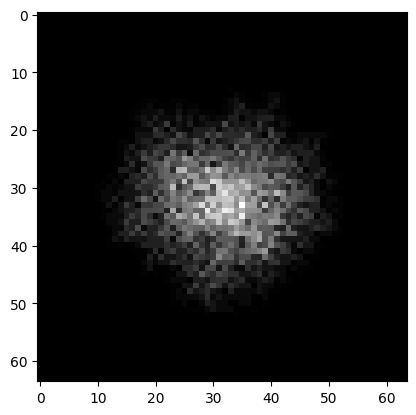

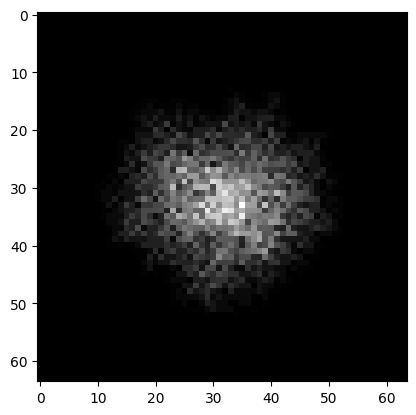

tf.Tensor(0.037122633, shape=(), dtype=float32)
tf.Tensor(0.02998272, shape=(), dtype=float32)
tf.Tensor(0.02973537, shape=(), dtype=float32)
tf.Tensor(0.032790434, shape=(), dtype=float32)
tf.Tensor(0.031555537, shape=(), dtype=float32)


In [ ]:
check_loss = 1
batch = tf.repeat(seed, 50, axis=0)
loss = 1
epochs = 100
for epoch in range(epochs):
    steps = np.random.randint(16, 32)
    loss = train_step(batch, target, steps)
    if epoch % 5 == 0:
      get_image()
    print(loss)

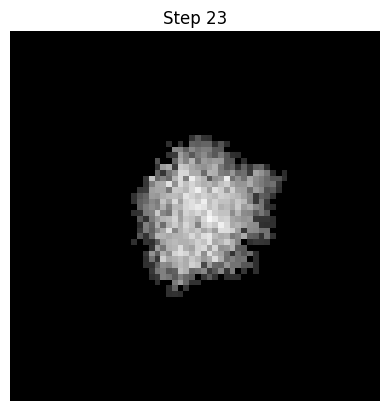

In [ ]:

import matplotlib.animation as animation
from IPython.display import HTML


# Generate rollout
state = seed
frames = []

for t in range(24):
    frames.append(state[0, :, :, 0].numpy())
    state = nca_step(state, model)
    state = alive_check(state)

# Create animation
fig, ax = plt.subplots()

im = ax.imshow(frames[0], cmap='gray', vmin=0, vmax=1)
ax.axis('off')

def update(frame):
    im.set_array(frames[frame])
    ax.set_title(f"Step {frame}")
    return [im]

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=100,
    blit=True
)

HTML(ani.to_jshtml())

Now to make it persist